In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import xgboost as xgb
import seaborn as sns


from sklearn.metrics import mean_squared_error


import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

In [117]:
df=pd.read_csv(r"C:\Users\SOLOMON\Downloads\Telegram Desktop\weatherdata.csv")

In [118]:
df

,Date,Longitude,Latitude,Elevation,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar,Precipitation
0,1/1/79,37.5,6.71292,1494,30.713,11.719,1.595418,0.418255,23.386395,0.000000
1,1/2/79,37.5,6.71292,1494,30.872,10.407,1.726672,0.432899,25.572441,0.000000
2,1/3/79,37.5,6.71292,1494,28.579,10.795,1.870545,0.456901,25.568213,0.000000
3,1/4/79,37.5,6.71292,1494,29.383,10.712,1.704374,0.463286,25.659900,0.000000
4,1/5/79,37.5,6.71292,1494,30.837,9.487,1.719667,0.394840,25.737013,0.000000
...,...,...,...,...,...,...,...,...,...,...
12982,7/27/14,37.5,6.71292,1494,21.351,15.630,1.123813,0.898494,15.266439,33.345219
12983,7/28/14,37.5,6.71292,1494,25.326,15.266,1.128937,0.840943,21.724500,11.767387
12984,7/29/14,37.5,6.71292,1494,23.138,13.402,1.297933,0.799027,18.358496,1.153566
12985,7/30/14,37.5,6.71292,1494,25.306,12.483,1.690213,0.739780,23.324918,0.418854


In [119]:
df.columns

Index(['Date', 'Longitude', 'Latitude', 'Elevation', 'Max Temperature',
       'Min Temperature', 'Wind', 'Relative Humidity', 'Solar',
       'Precipitation'],
      dtype='object')

In [120]:
df = df.drop(
    columns=['Longitude', 'Latitude', 'Elevation'])

In [121]:
df

,Date,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar,Precipitation
0,1/1/79,30.713,11.719,1.595418,0.418255,23.386395,0.000000
1,1/2/79,30.872,10.407,1.726672,0.432899,25.572441,0.000000
2,1/3/79,28.579,10.795,1.870545,0.456901,25.568213,0.000000
3,1/4/79,29.383,10.712,1.704374,0.463286,25.659900,0.000000
4,1/5/79,30.837,9.487,1.719667,0.394840,25.737013,0.000000
...,...,...,...,...,...,...,...
12982,7/27/14,21.351,15.630,1.123813,0.898494,15.266439,33.345219
12983,7/28/14,25.326,15.266,1.128937,0.840943,21.724500,11.767387
12984,7/29/14,23.138,13.402,1.297933,0.799027,18.358496,1.153566
12985,7/30/14,25.306,12.483,1.690213,0.739780,23.324918,0.418854


In [122]:
df = df.set_index('Date')

In [123]:
df.index = pd.to_datetime(df.index, dayfirst=True)

C:\Users\SOLOMON\AppData\Local\Temp\ipykernel_28024\3764146352.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df.index = pd.to_datetime(df.index, dayfirst=True)


In [142]:
df.columns

Index(['Max Temperature', 'Min Temperature', 'Wind', 'Relative Humidity',
       'Solar', 'Precipitation', 'dayofweek', 'quarter', 'month', 'dayofyear',
       'year', 'weekofyear', 'week', 'monthofyear'],
      dtype='object')

<Axes: title={'center': 'Weather Forcast'}, xlabel='Date'>

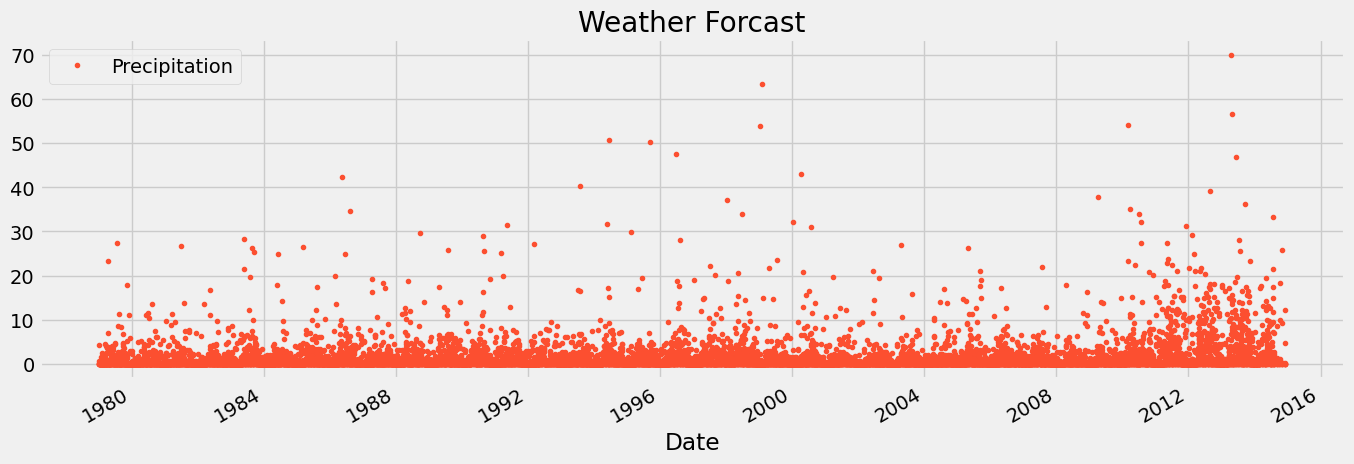

In [143]:
dfn=df.drop(columns=['Max Temperature', 'Min Temperature', 'Wind', 'Relative Humidity',
       'Solar', 'dayofweek', 'quarter', 'month', 'dayofyear',
       'year', 'weekofyear', 'week', 'monthofyear'])

color_pallete = sns.color_palette()
dfn.plot(style='.', figsize=(15,5), color= color_pallete[1], title="Weather Forcast")

In [145]:
trainn = dfn.loc[df.index<= '2014-07-01']
testn = dfn.loc[df.index >= '2014-07-02']

In [146]:
len(trainn), len(testn)

(12927, 60)

In [126]:
train = df.loc[df.index<= '2014-07-01']
test = df.loc[df.index >= '2014-07-02']

In [127]:
len(train), len(test)

(12927, 60)

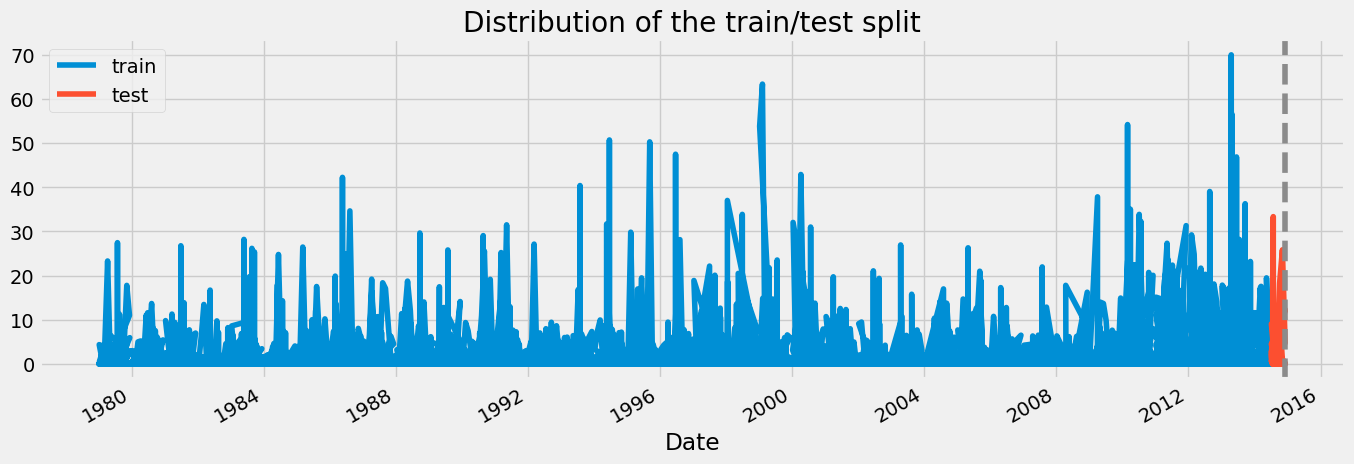

In [147]:
fig, ax = plt.subplots(figsize = (15, 5))
trainn.plot(ax = ax, label = "Training", title = "Distribution of the train/test split")
testn.plot(ax = ax, label = "Testing")
ax.axvline('2014-11-30', color = color_pallete[4], ls = '--')
ax.legend(['train','test'])
plt.show()

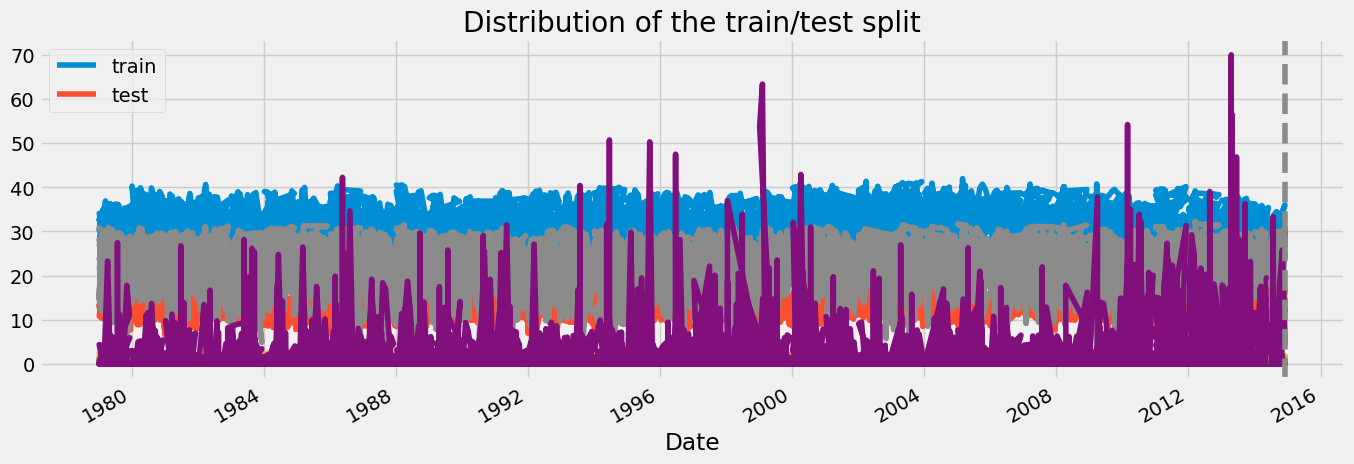

In [128]:
fig, ax = plt.subplots(figsize = (15, 5))
train.plot(ax = ax, label = "Training", title = "Distribution of the train/test split")
test.plot(ax = ax, label = "Testing")
ax.axvline('2014-11-30', color = color_pallete[4], ls = '--')
ax.legend(['train','test'])
plt.show()

In [129]:
def feature_extraction(df):
    df = df.copy()
    
    
    df['dayofweek'] = df.index.day_of_week
    df['quarter'] = df.index.quarter
    df['month'] = df.index.month
    df['dayofyear'] = df.index.day_of_year
    df['year'] = df.index.year
    iso = df.index.isocalendar()

    df['weekofyear'] = iso.week
    df['week'] = iso.week
    df['monthofyear'] = df.index.month
    return df
df = feature_extraction(df)

In [130]:
df.columns

Index(['Max Temperature', 'Min Temperature', 'Wind', 'Relative Humidity',
       'Solar', 'Precipitation', 'dayofweek', 'quarter', 'month', 'dayofyear',
       'year', 'weekofyear', 'week', 'monthofyear'],
      dtype='object')

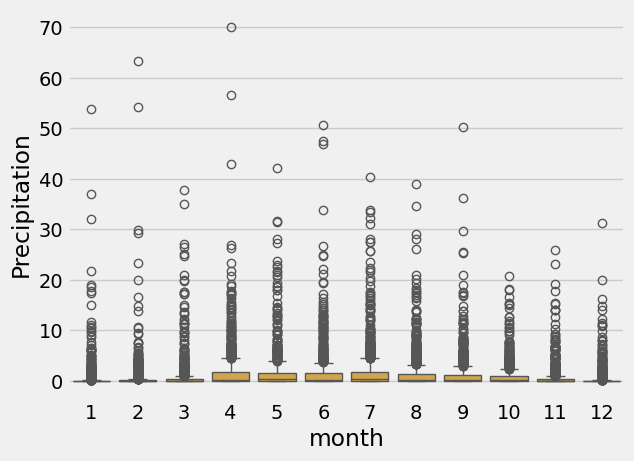

In [131]:

sns.boxplot(data=df, x='month', y = 'Precipitation', color=color_pallete[2])
ax.set_title('Month')
plt.show()

In [132]:
train = feature_extraction(train)
test = feature_extraction(test)

In [133]:
Features  = [ 'Max Temperature', 'Min Temperature', 'Wind', 'Relative Humidity',
       'Solar', 'dayofweek', 'quarter', 'month', 'dayofyear',
       'year', 'weekofyear', 'week', 'monthofyear']
Target = 'Precipitation'

In [134]:
X_train = train[Features]
Y_train = train[Target]
X_test = test[Features]
Y_test = test[Target]

In [135]:
X_train.shape, Y_train.shape, X_test.shape, Y_test.shape

((12927, 13), (12927,), (60, 13), (60,))

In [136]:
regression = xgb.XGBRegressor(n_estimators = 200, early_stopping_rounds = True, learning_rate = 0.001)
regression.fit(X_train, Y_train, eval_set = [(X_train, Y_train), (X_test, Y_test)], verbose = True)

[0]	validation_0-rmse:3.32249	validation_1-rmse:7.66064
[1]	validation_0-rmse:3.32070	validation_1-rmse:7.65750
[2]	validation_0-rmse:3.31892	validation_1-rmse:7.65432
[3]	validation_0-rmse:3.31714	validation_1-rmse:7.65119
[4]	validation_0-rmse:3.31536	validation_1-rmse:7.64802
[5]	validation_0-rmse:3.31358	validation_1-rmse:7.64489
[6]	validation_0-rmse:3.31180	validation_1-rmse:7.64174
[7]	validation_0-rmse:3.31003	validation_1-rmse:7.63861
[8]	validation_0-rmse:3.30826	validation_1-rmse:7.63546
[9]	validation_0-rmse:3.30649	validation_1-rmse:7.63231
[10]	validation_0-rmse:3.30472	validation_1-rmse:7.62920
[11]	validation_0-rmse:3.30296	validation_1-rmse:7.62606
[12]	validation_0-rmse:3.30120	validation_1-rmse:7.62296
[13]	validation_0-rmse:3.29944	validation_1-rmse:7.61982
[14]	validation_0-rmse:3.29768	validation_1-rmse:7.61673
[15]	validation_0-rmse:3.29593	validation_1-rmse:7.61359
[16]	validation_0-rmse:3.29418	validation_1-rmse:7.61050
[17]	validation_0-rmse:3.29242	validation

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,True
,enable_categorical,True
,eval_metric,None


In [137]:
regression.feature_importances_

array([0.02361946, 0.17531396, 0.04444611, 0.53250885, 0.05062597,
       0.01684238, 0.        , 0.02394327, 0.05829825, 0.07440176,
       0.        , 0.        , 0.        ], dtype=float32)

In [138]:
feature_stat = pd.DataFrame(data = regression.feature_importances_, 
             index= regression.feature_names_in_,
            columns = ['importance'])

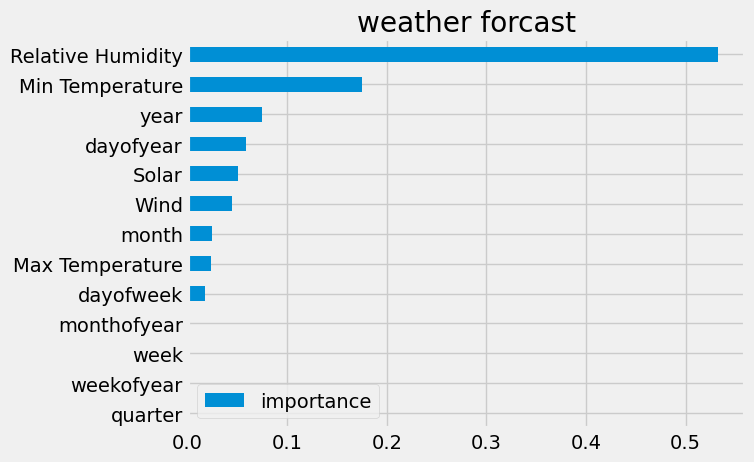

In [139]:
feature_stat.sort_values('importance').plot(kind = 'barh', title = 'weather forcast')
plt.show()

In [140]:
test['Prediction'] = regression.predict(X_test)

In [141]:
test

,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar,Precipitation,dayofweek,quarter,month,dayofyear,year,weekofyear,week,monthofyear,Prediction
Date,,,,,,,,,,,,,,,
2014-08-01,32.521,14.128,1.261902,0.461411,24.019660,0.000000,4,3,8,213,2014,31,31,8,0.961477
2014-09-01,31.257,14.319,1.476756,0.561609,17.690377,0.099564,0,3,9,244,2014,36,36,9,0.980360
2014-10-01,32.095,15.044,1.401816,0.503281,22.825782,0.048065,2,4,10,274,2014,40,40,10,0.971144
2014-11-01,32.761,12.630,1.490344,0.453660,25.939256,0.000000,5,4,11,305,2014,44,44,11,0.961477
2014-12-01,29.609,12.387,1.588361,0.426592,25.410203,0.000000,0,4,12,335,2014,49,49,12,0.954681
2014-07-02,32.737,16.417,1.090291,0.549299,18.772779,2.023888,2,3,7,183,2014,27,27,7,1.027750
2014-08-02,29.769,16.247,1.084452,0.635666,11.591852,7.044980,5,3,8,214,2014,31,31,8,1.113235
2014-09-02,33.613,13.252,1.151467,0.596972,23.879885,0.000000,1,3,9,245,2014,36,36,9,1.001063
2014-10-02,31.108,14.483,1.753840,0.547500,25.673681,0.000000,3,4,10,275,2014,40,40,10,0.975558


In [ ]:
##########################################################

In [6]:
df_n=pd.read_csv(r"C:\Users\SOLOMON\Downloads\Telegram Desktop\weatherdata.csv")



In [7]:
df_n["Date"]=pd.to_datetime(df_n["Date"])

C:\Users\SOLOMON\AppData\Local\Temp\ipykernel_30856\1662225530.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_n["Date"]=pd.to_datetime(df_n["Date"])


In [8]:
df_n

,Date,Longitude,Latitude,Elevation,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar,Precipitation
0,1979-01-01,37.5,6.71292,1494,30.713,11.719,1.595418,0.418255,23.386395,0.000000
1,1979-01-02,37.5,6.71292,1494,30.872,10.407,1.726672,0.432899,25.572441,0.000000
2,1979-01-03,37.5,6.71292,1494,28.579,10.795,1.870545,0.456901,25.568213,0.000000
3,1979-01-04,37.5,6.71292,1494,29.383,10.712,1.704374,0.463286,25.659900,0.000000
4,1979-01-05,37.5,6.71292,1494,30.837,9.487,1.719667,0.394840,25.737013,0.000000
...,...,...,...,...,...,...,...,...,...,...
12982,2014-07-27,37.5,6.71292,1494,21.351,15.630,1.123813,0.898494,15.266439,33.345219
12983,2014-07-28,37.5,6.71292,1494,25.326,15.266,1.128937,0.840943,21.724500,11.767387
12984,2014-07-29,37.5,6.71292,1494,23.138,13.402,1.297933,0.799027,18.358496,1.153566
12985,2014-07-30,37.5,6.71292,1494,25.306,12.483,1.690213,0.739780,23.324918,0.418854


In [9]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.arima.model import ARIMA

sns.set_theme(style="whitegrid")

# ---------------------------------------------------------
# 1. Load & Aggregate Daily Data Correctly
# ---------------------------------------------------------
target_col = "Precipitation"

# Convert Date to datetime first
df_n["Date"] = pd.to_datetime(df_n["Date"])

# Sort chronologically by Date
df_n = df_n.sort_values(by="Date")

# Aggregate daily totals for Precipitation & daily averages for weather features
weather_features = [
    "Max Temperature",
    "Min Temperature",
    "Wind",
    "Relative Humidity",
    "Solar",
]
aggregation_dict = {target_col: "sum"}
for col in weather_features:
  if col in df_n.columns:
    aggregation_dict[col] = "mean"

ts_data = df_n.groupby("Date").agg(aggregation_dict).reset_index()

# Set index to Date (FIXED: Previously you passed a list of missing columns)
ts_data.set_index("Date", inplace=True)
ts_data = ts_data.asfreq("D").fillna(0)  # Ensure daily frequency

# ---------------------------------------------------------
# 2. Feature Engineering (Lags, Rolling Stats, Exogenous Weather)
# ---------------------------------------------------------
df_ml = ts_data.copy()

# Create lag features for Precipitation
for lag in [1, 2, 3, 7, 14, 30]:
  df_ml[f"lag_{lag}"] = df_ml[target_col].shift(lag)

# Create rolling window statistics
df_ml["rolling_mean_7"] = df_ml[target_col].shift(1).rolling(7).mean()
df_ml["rolling_std_7"] = df_ml[target_col].shift(1).rolling(7).std()

# Drop rows with NaN from lagging
df_ml.dropna(inplace=True)

# ---------------------------------------------------------
# 3. Time-Based Train/Test Split (Sequential Split)
# ---------------------------------------------------------
test_days = 60  # Hold out last 60 days for testing

X = df_ml.drop(columns=[target_col])
y = df_ml[target_col]

X_train, X_test = X.iloc[:-test_days], X.iloc[-test_days:]
y_train, y_test = y.iloc[:-test_days], y.iloc[-test_days:]

# ---------------------------------------------------------
# 4. Train & Predict with Multiple Algorithms
# ---------------------------------------------------------
predictions = {}
results = []

# --- Model A: Machine Learning Regressors ---
ml_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

for name, model in ml_models.items():
  model.fit(X_train, y_train)
  preds = model.predict(X_test)
  predictions[name] = pd.Series(preds, index=y_test.index)

  mae = mean_absolute_error(y_test, preds)
  rmse = np.sqrt(mean_squared_error(y_test, preds))
  r2 = r2_score(y_test, preds)
  results.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2 Score": r2})

# --- Model B: Statistical Time-Series Model (ARIMA) ---
try:
  arima_model = ARIMA(y_train, order=(7, 1, 1)).fit()
  arima_preds = arima_model.forecast(steps=test_days)
  predictions["ARIMA(7,1,1)"] = arima_preds

  mae = mean_absolute_error(y_test, arima_preds)
  rmse = np.sqrt(mean_squared_error(y_test, arima_preds))
  r2 = r2_score(y_test, arima_preds)
  results.append({
      "Model": "ARIMA(7,1,1)",
      "MAE": mae,
      "RMSE": rmse,
      "R2 Score": r2,
  })
except Exception as e:
  print(f"ARIMA fitting skipped due to: {e}")

# Save metrics summary
results_df = pd.DataFrame(results).sort_values(by="RMSE")
print("\n=== Time Series Model Comparison ===")
print(results_df.to_string(index=False))


=== Time Series Model Comparison ===
            Model      MAE     RMSE  R2 Score
Gradient Boosting 2.384030 3.546850  0.675405
    Random Forest 2.612353 3.763631  0.634515
Linear Regression 3.722563 5.536834  0.208995
 Ridge Regression 3.723033 5.537031  0.208939
     ARIMA(7,1,1) 5.044058 6.337800 -0.036413


In [ ]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge,Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.arima.model import ARIMA

sns.set_theme(style="whitegrid")

In [38]:
df_n=pd.read_csv(r"C:\Users\SOLOMON\Downloads\Telegram Desktop\weatherdata.csv")
dfy=pd.read_csv(r"C:\Users\SOLOMON\Downloads\Telegram Desktop\weatherdata.csv")


In [40]:
df_n

,Date,Longitude,Latitude,Elevation,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar,Precipitation
0,1/1/79,37.5,6.71292,1494,30.713,11.719,1.595418,0.418255,23.386395,0.000000
1,1/2/79,37.5,6.71292,1494,30.872,10.407,1.726672,0.432899,25.572441,0.000000
2,1/3/79,37.5,6.71292,1494,28.579,10.795,1.870545,0.456901,25.568213,0.000000
3,1/4/79,37.5,6.71292,1494,29.383,10.712,1.704374,0.463286,25.659900,0.000000
4,1/5/79,37.5,6.71292,1494,30.837,9.487,1.719667,0.394840,25.737013,0.000000
...,...,...,...,...,...,...,...,...,...,...
12982,7/27/14,37.5,6.71292,1494,21.351,15.630,1.123813,0.898494,15.266439,33.345219
12983,7/28/14,37.5,6.71292,1494,25.326,15.266,1.128937,0.840943,21.724500,11.767387
12984,7/29/14,37.5,6.71292,1494,23.138,13.402,1.297933,0.799027,18.358496,1.153566
12985,7/30/14,37.5,6.71292,1494,25.306,12.483,1.690213,0.739780,23.324918,0.418854


In [42]:
import pandas as pd

# Make sure Date is datetime
dfy['Date'] = pd.to_datetime(dfy['Date'])

# Extract month and day
dfy['Month'] = dfy['Date'].dt.month
dfy['Day'] = dfy['Date'].dt.day

# Select numeric columns
numeric_cols = dfy.select_dtypes(include='number').columns

# Remove Month and Day from the columns to aggregate
numeric_cols = numeric_cols.difference(['Month', 'Day'])

# Combine all years by month/day
one_year = (
    dfy.groupby(['Month', 'Day'])[numeric_cols]
      .mean()
      .reset_index()
)



In [12]:
df_n["Date"]=pd.to_datetime(df_n["Date"])

C:\Users\SOLOMON\AppData\Local\Temp\ipykernel_30856\1662225530.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_n["Date"]=pd.to_datetime(df_n["Date"])


In [13]:
target_col = "Precipitation"
df_n = df_n.sort_values(by="Date")

In [14]:
df_n

,Date,Longitude,Latitude,Elevation,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar,Precipitation
0,1979-01-01,37.5,6.71292,1494,30.713,11.719,1.595418,0.418255,23.386395,0.000000
1,1979-01-02,37.5,6.71292,1494,30.872,10.407,1.726672,0.432899,25.572441,0.000000
2,1979-01-03,37.5,6.71292,1494,28.579,10.795,1.870545,0.456901,25.568213,0.000000
3,1979-01-04,37.5,6.71292,1494,29.383,10.712,1.704374,0.463286,25.659900,0.000000
4,1979-01-05,37.5,6.71292,1494,30.837,9.487,1.719667,0.394840,25.737013,0.000000
...,...,...,...,...,...,...,...,...,...,...
12982,2014-07-27,37.5,6.71292,1494,21.351,15.630,1.123813,0.898494,15.266439,33.345219
12983,2014-07-28,37.5,6.71292,1494,25.326,15.266,1.128937,0.840943,21.724500,11.767387
12984,2014-07-29,37.5,6.71292,1494,23.138,13.402,1.297933,0.799027,18.358496,1.153566
12985,2014-07-30,37.5,6.71292,1494,25.306,12.483,1.690213,0.739780,23.324918,0.418854


In [15]:
weather_features = [
    "Max Temperature",
    "Min Temperature",
    "Wind",
    "Relative Humidity",
    "Solar",
]

In [16]:
aggregation_dict = {target_col: "sum"}
for col in weather_features:
  if col in df_n.columns:
    aggregation_dict[col] = "mean"

In [17]:

ts_data = df_n.groupby("Date").agg(aggregation_dict).reset_index()



In [18]:
ts_data

,Date,Precipitation,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar
0,1979-01-01,0.000000,30.713,11.719,1.595418,0.418255,23.386395
1,1979-01-02,0.000000,30.872,10.407,1.726672,0.432899,25.572441
2,1979-01-03,0.000000,28.579,10.795,1.870545,0.456901,25.568213
3,1979-01-04,0.000000,29.383,10.712,1.704374,0.463286,25.659900
4,1979-01-05,0.000000,30.837,9.487,1.719667,0.394840,25.737013
...,...,...,...,...,...,...,...
12982,2014-07-27,33.345219,21.351,15.630,1.123813,0.898494,15.266439
12983,2014-07-28,11.767387,25.326,15.266,1.128937,0.840943,21.724500
12984,2014-07-29,1.153566,23.138,13.402,1.297933,0.799027,18.358496
12985,2014-07-30,0.418854,25.306,12.483,1.690213,0.739780,23.324918


In [19]:
ts_data.set_index("Date", inplace=True)
ts_data = ts_data.asfreq("D").fillna(0)

In [20]:
ts_data

,Precipitation,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar
Date,,,,,,
1979-01-01,0.000000,30.713,11.719,1.595418,0.418255,23.386395
1979-01-02,0.000000,30.872,10.407,1.726672,0.432899,25.572441
1979-01-03,0.000000,28.579,10.795,1.870545,0.456901,25.568213
1979-01-04,0.000000,29.383,10.712,1.704374,0.463286,25.659900
1979-01-05,0.000000,30.837,9.487,1.719667,0.394840,25.737013
...,...,...,...,...,...,...
2014-07-27,33.345219,21.351,15.630,1.123813,0.898494,15.266439
2014-07-28,11.767387,25.326,15.266,1.128937,0.840943,21.724500
2014-07-29,1.153566,23.138,13.402,1.297933,0.799027,18.358496


In [21]:
df_ml = ts_data.copy()

In [22]:
df_ml

,Precipitation,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar
Date,,,,,,
1979-01-01,0.000000,30.713,11.719,1.595418,0.418255,23.386395
1979-01-02,0.000000,30.872,10.407,1.726672,0.432899,25.572441
1979-01-03,0.000000,28.579,10.795,1.870545,0.456901,25.568213
1979-01-04,0.000000,29.383,10.712,1.704374,0.463286,25.659900
1979-01-05,0.000000,30.837,9.487,1.719667,0.394840,25.737013
...,...,...,...,...,...,...
2014-07-27,33.345219,21.351,15.630,1.123813,0.898494,15.266439
2014-07-28,11.767387,25.326,15.266,1.128937,0.840943,21.724500
2014-07-29,1.153566,23.138,13.402,1.297933,0.799027,18.358496


In [23]:
for lag in [1, 2, 3, 7, 14, 30]:
  df_ml[f"lag_{lag}"] = df_ml[target_col].shift(lag)

In [24]:
df_ml

,Precipitation,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar,lag_1,lag_2,lag_3,lag_7,lag_14,lag_30
Date,,,,,,,,,,,,
1979-01-01,0.000000,30.713,11.719,1.595418,0.418255,23.386395,NaN,NaN,NaN,NaN,NaN,NaN
1979-01-02,0.000000,30.872,10.407,1.726672,0.432899,25.572441,0.000000,NaN,NaN,NaN,NaN,NaN
1979-01-03,0.000000,28.579,10.795,1.870545,0.456901,25.568213,0.000000,0.000000,NaN,NaN,NaN,NaN
1979-01-04,0.000000,29.383,10.712,1.704374,0.463286,25.659900,0.000000,0.000000,0.000000,NaN,NaN,NaN
1979-01-05,0.000000,30.837,9.487,1.719667,0.394840,25.737013,0.000000,0.000000,0.000000,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
2014-07-27,33.345219,21.351,15.630,1.123813,0.898494,15.266439,14.998059,1.335526,21.467977,0.048065,0.460052,0.075531
2014-07-28,11.767387,25.326,15.266,1.128937,0.840943,21.724500,33.345219,14.998059,1.335526,17.351529,3.948209,0.022316
2014-07-29,1.153566,23.138,13.402,1.297933,0.799027,18.358496,11.767387,33.345219,14.998059,7.230374,4.895783,0.000000


In [25]:
df_ml["rolling_mean_7"] = df_ml[target_col].shift(1).rolling(7).mean()
df_ml["rolling_std_7"] = df_ml[target_col].shift(1).rolling(7).std()

In [26]:
df_ml

,Precipitation,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar,lag_1,lag_2,lag_3,lag_7,lag_14,lag_30,rolling_mean_7,rolling_std_7
Date,,,,,,,,,,,,,,
1979-01-01,0.000000,30.713,11.719,1.595418,0.418255,23.386395,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1979-01-02,0.000000,30.872,10.407,1.726672,0.432899,25.572441,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1979-01-03,0.000000,28.579,10.795,1.870545,0.456901,25.568213,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
1979-01-04,0.000000,29.383,10.712,1.704374,0.463286,25.659900,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
1979-01-05,0.000000,30.837,9.487,1.719667,0.394840,25.737013,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2014-07-27,33.345219,21.351,15.630,1.123813,0.898494,15.266439,14.998059,1.335526,21.467977,0.048065,0.460052,0.075531,10.280310,8.082855
2014-07-28,11.767387,25.326,15.266,1.128937,0.840943,21.724500,33.345219,14.998059,1.335526,17.351529,3.948209,0.022316,15.037047,10.495242
2014-07-29,1.153566,23.138,13.402,1.297933,0.799027,18.358496,11.767387,33.345219,14.998059,7.230374,4.895783,0.000000,14.239312,10.502221


In [27]:
df_ml.dropna(inplace=True)

In [28]:
df_ml

,Precipitation,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar,lag_1,lag_2,lag_3,lag_7,lag_14,lag_30,rolling_mean_7,rolling_std_7
Date,,,,,,,,,,,,,,
1979-01-31,0.003433,32.308,11.245,1.302159,0.589203,25.777343,0.000000,1.575851,0.000000,0.497818,0.000000,0.000000,0.415666,0.552462
1979-02-01,0.010300,30.357,13.131,1.310149,0.619369,14.947704,0.003433,0.000000,1.575851,0.504684,0.000000,0.000000,0.345039,0.571483
1979-02-02,0.000000,30.841,11.800,1.779880,0.592751,25.217440,0.010300,0.003433,0.000000,0.168228,0.000000,0.000000,0.274413,0.578965
1979-02-03,0.000000,31.832,11.581,1.768698,0.599550,26.066642,0.000000,0.010300,0.003433,0.163078,0.000000,0.000000,0.250380,0.587535
1979-02-04,0.000000,27.458,12.734,1.282378,0.594471,15.279186,0.000000,0.000000,0.010300,0.000000,0.000000,0.000000,0.227083,0.594763
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2014-07-27,33.345219,21.351,15.630,1.123813,0.898494,15.266439,14.998059,1.335526,21.467977,0.048065,0.460052,0.075531,10.280310,8.082855
2014-07-28,11.767387,25.326,15.266,1.128937,0.840943,21.724500,33.345219,14.998059,1.335526,17.351529,3.948209,0.022316,15.037047,10.495242
2014-07-29,1.153566,23.138,13.402,1.297933,0.799027,18.358496,11.767387,33.345219,14.998059,7.230374,4.895783,0.000000,14.239312,10.502221


In [29]:
test_days = 60  # Hold out last 60 days for testing

X = df_ml.drop(columns=[target_col])
y = df_ml[target_col]

X_train, X_test = X.iloc[:-test_days], X.iloc[-test_days:]
y_train, y_test = y.iloc[:-test_days], y.iloc[-test_days:]


In [32]:
predictions = {}
results = []

In [34]:
ml_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=100.0, max_iter=10000, random_state=42),
    "KNN": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

In [35]:
for name, model in ml_models.items():
  model.fit(X_train, y_train)
  preds = model.predict(X_test)
  predictions[name] = pd.Series(preds, index=y_test.index)

  mae = mean_absolute_error(y_test, preds)
  rmse = np.sqrt(mean_squared_error(y_test, preds))
  r2 = r2_score(y_test, preds)
  results.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2 Score": r2})

In [36]:
try:
  arima_model = ARIMA(y_train, order=(7, 1, 1)).fit()
  arima_preds = arima_model.forecast(steps=test_days)
  predictions["ARIMA(7,1,1)"] = pd.Series(
      arima_preds.values, index=y_test.index
  )

  mae = mean_absolute_error(y_test, arima_preds)
  rmse = np.sqrt(mean_squared_error(y_test, arima_preds))
  r2 = r2_score(y_test, arima_preds)
  results.append({
      "Model": "ARIMA(7,1,1)",
      "MAE": mae,
      "RMSE": rmse,
      "R2 Score": r2,
  })
except Exception as e:
  print(f"ARIMA fitting skipped due to: {e}")

In [37]:
results_df = pd.DataFrame(results).sort_values(by="RMSE")
print("\n=== Time Series Model Comparison ===")
print(results_df.to_string(index=False))


=== Time Series Model Comparison ===
            Model      MAE     RMSE  R2 Score
Gradient Boosting 2.384030 3.546850  0.675405
    Random Forest 2.612353 3.763631  0.634515
Linear Regression 3.722563 5.536834  0.208995
 Ridge Regression 3.723033 5.537031  0.208939
    Decision Tree 3.366967 6.256752 -0.010075
     ARIMA(7,1,1) 5.044058 6.337800 -0.036413
              KNN 3.935858 6.527435 -0.099363
            Lasso 3.831425 6.896441 -0.227174



=== Time Series Model Comparison ===
            Model      MAE     RMSE  R2 Score
Gradient Boosting 2.384030 3.546850  0.675405
    Random Forest 2.612353 3.763631  0.634515
Linear Regression 3.722563 5.536834  0.208995
 Ridge Regression 3.723033 5.537031  0.208939
    Decision Tree 3.366967 6.256752 -0.010075
     ARIMA(7,1,1) 5.044058 6.337800 -0.036413
              KNN 3.935858 6.527435 -0.099363
            Lasso 3.831425 6.896441 -0.227174


C:\Users\SOLOMON\AppData\Local\Temp\ipykernel_30856\1550261106.py:137: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="RMSE", y="Model", palette="crest", ax=ax1)


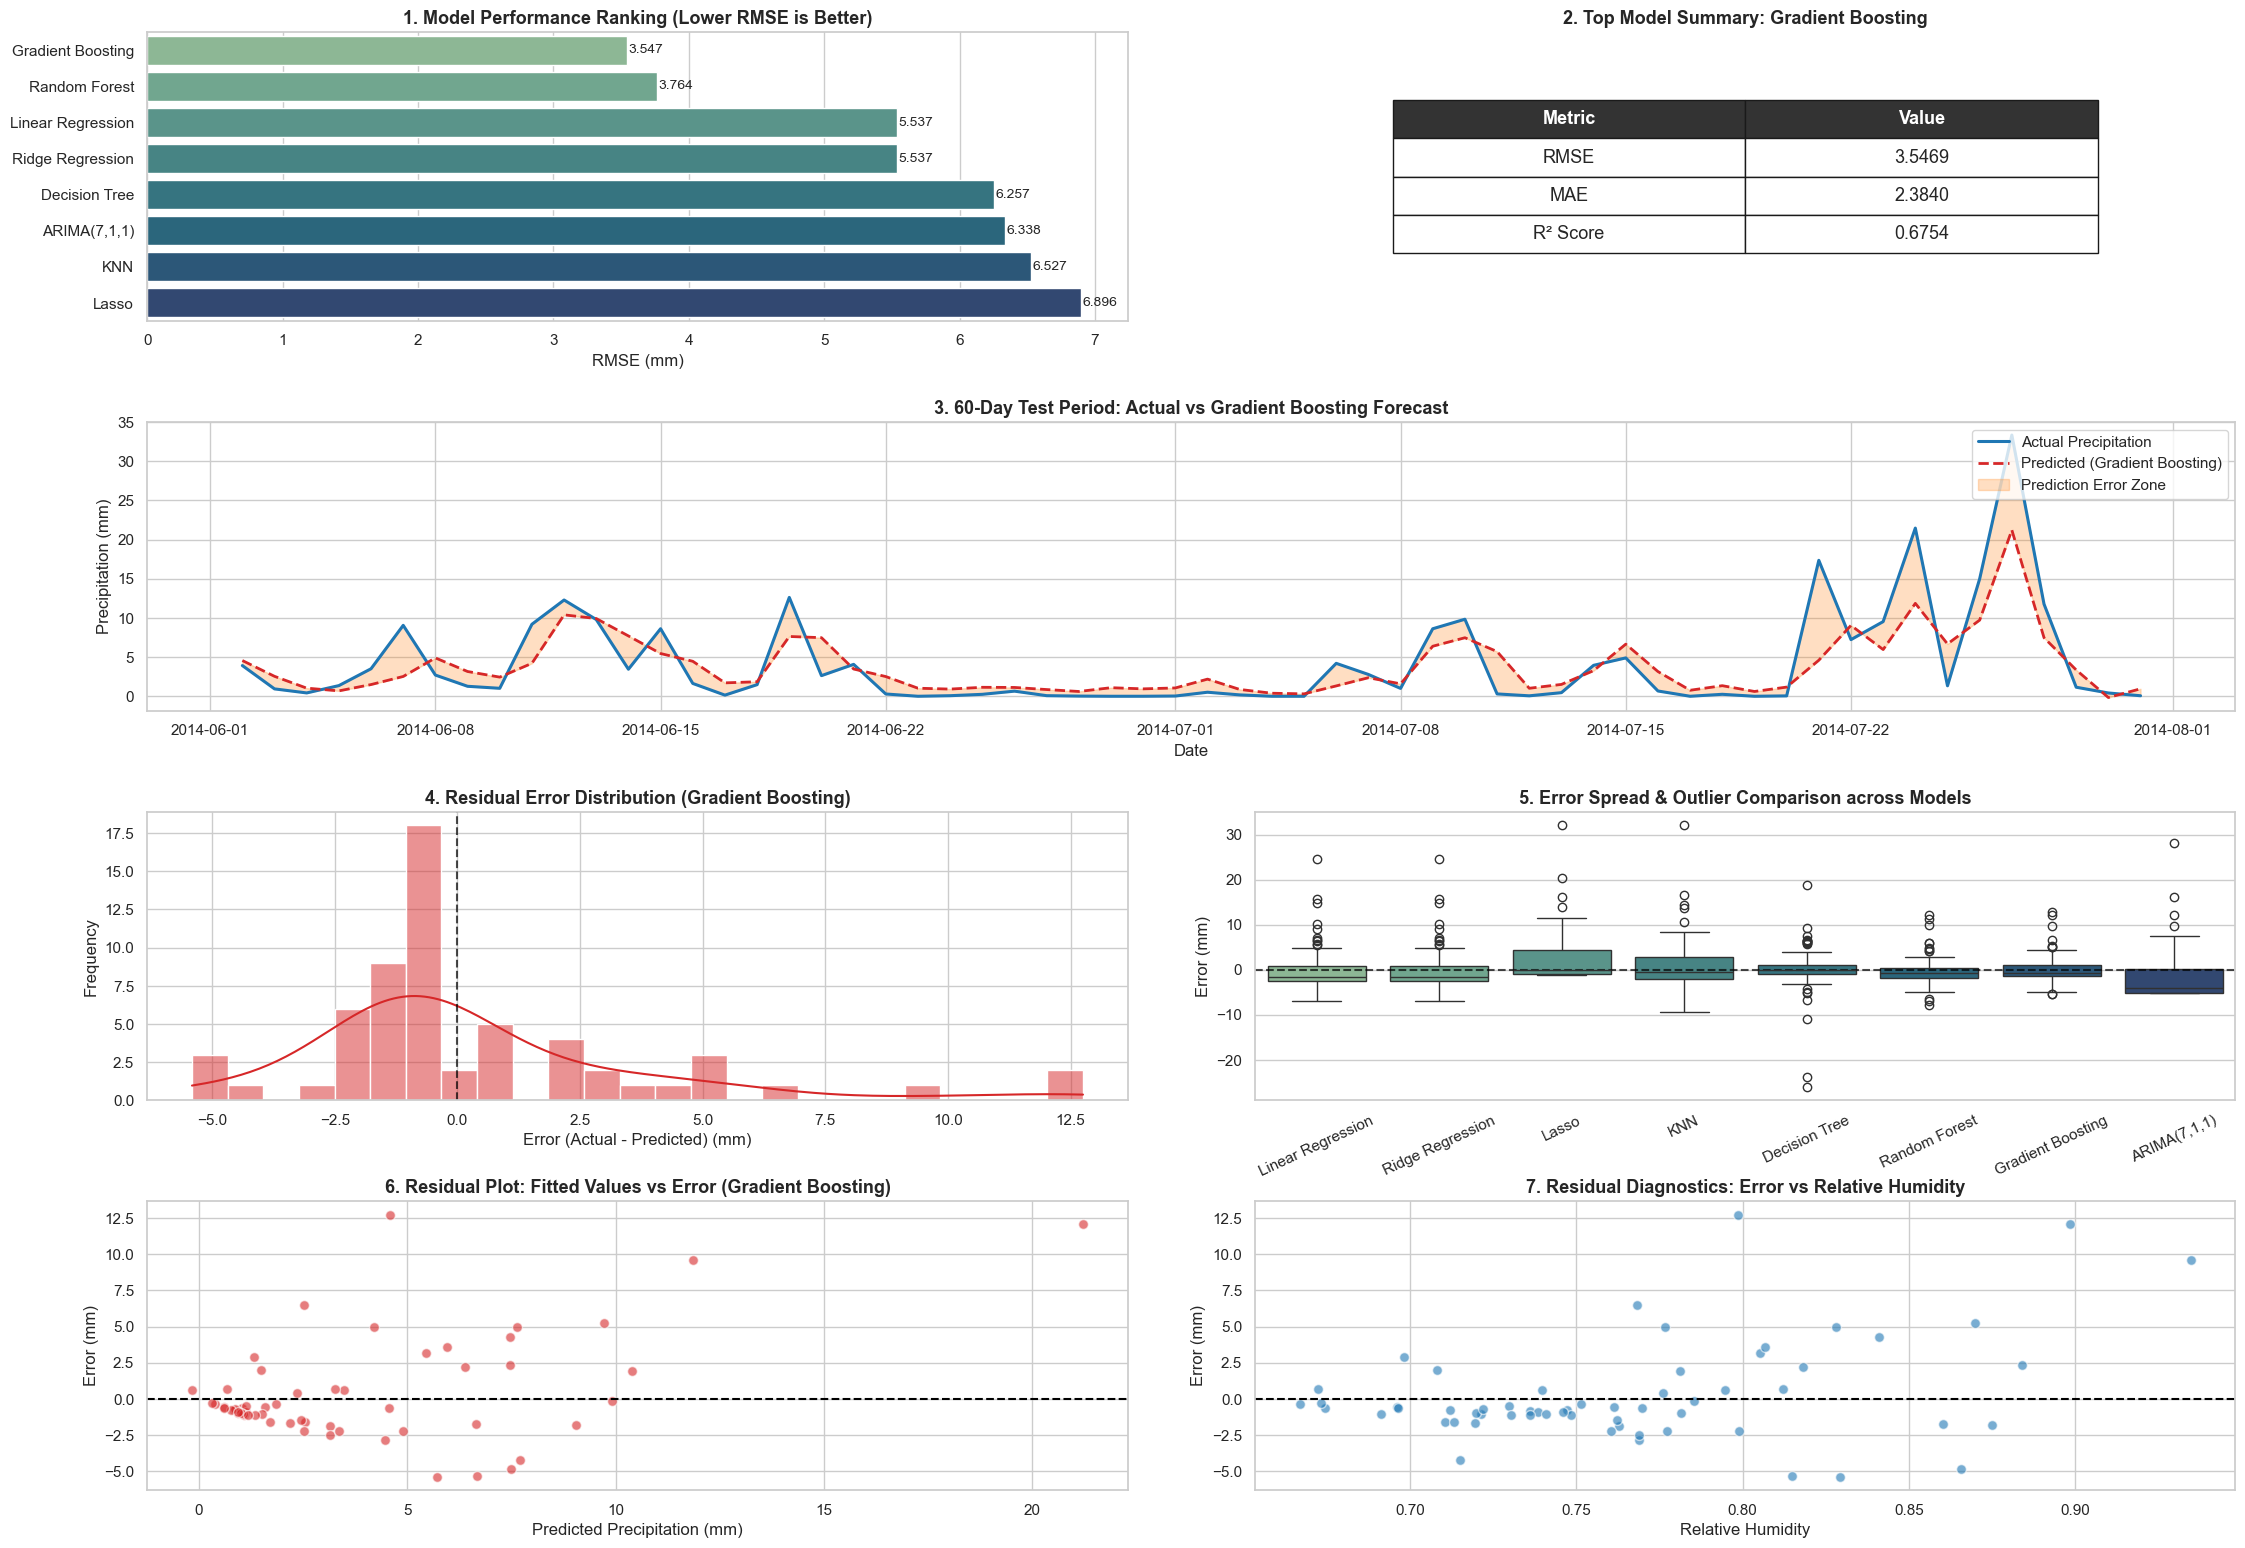

In [10]:



best_model_name = results_df.iloc[0]["Model"]
best_preds = predictions[best_model_name]
best_errors = y_test - best_preds

fig = plt.figure(figsize=(24, 18))
gs = gridspec.GridSpec(4, 4, figure=fig, hspace=0.35, wspace=0.3)

# Panel 1: Model Comparison Bar Plot
ax1 = fig.add_subplot(gs[0, 0:2])
sns.barplot(data=results_df, x="RMSE", y="Model", palette="crest", ax=ax1)
ax1.set_title(
    "1. Model Performance Ranking (Lower RMSE is Better)",
    fontsize=13,
    fontweight="bold",
)
ax1.set_xlabel("RMSE (mm)")
ax1.set_ylabel("")

for p in ax1.patches:
  width = p.get_width()
  ax1.text(
      width + 0.01,
      p.get_y() + p.get_height() / 2,
      f"{width:.3f}",
      ha="left",
      va="center",
      fontsize=10,
  )

# Panel 2: Summary Metrics Table of Top Model
ax2 = fig.add_subplot(gs[0, 2:4])
ax2.axis("off")
table_data = [["Metric", "Value"]] + [
    ["RMSE", f"{results_df.iloc[0]['RMSE']:.4f}"],
    ["MAE", f"{results_df.iloc[0]['MAE']:.4f}"],
    ["R² Score", f"{results_df.iloc[0]['R2 Score']:.4f}"],
]
table = ax2.table(
    cellText=table_data, loc="center", cellLoc="center", colWidths=[0.3, 0.3]
)
table.auto_set_font_size(False)
table.set_fontsize(13)
table.scale(1.2, 2.3)
for (row, col), cell in table.get_celld().items():
  if row == 0:
    cell.set_text_props(weight="bold", color="white")
    cell.set_facecolor("#333333")
ax2.set_title(
    f"2. Top Model Summary: {best_model_name}", fontsize=13, fontweight="bold"
)

# Panel 3: 60-Day Time-Series Forecast Plot
ax3 = fig.add_subplot(gs[1, 0:4])
ax3.plot(
    y_test.index,
    y_test.values,
    label="Actual Precipitation",
    color="#1f77b4",
    linewidth=2.2,
)
ax3.plot(
    y_test.index,
    best_preds.values,
    label=f"Predicted ({best_model_name})",
    color="#d62728",
    linestyle="--",
    linewidth=2,
)
ax3.fill_between(
    y_test.index,
    y_test.values,
    best_preds.values,
    color="#ff7f0e",
    alpha=0.25,
    label="Prediction Error Zone",
)
ax3.set_title(
    f"3. 60-Day Test Period: Actual vs {best_model_name} Forecast",
    fontsize=13,
    fontweight="bold",
)
ax3.set_ylabel("Precipitation (mm)")
ax3.set_xlabel("Date")
ax3.legend(loc="upper right")

# Panel 4: Error Histogram & Density Curve
ax4 = fig.add_subplot(gs[2, 0:2])
sns.histplot(best_errors, bins=25, kde=True, color="#d62728", ax=ax4)
ax4.axvline(x=0, color="black", linestyle="--", alpha=0.7)
ax4.set_title(
    f"4. Residual Error Distribution ({best_model_name})",
    fontsize=13,
    fontweight="bold",
)
ax4.set_xlabel("Error (Actual - Predicted) (mm)")
ax4.set_ylabel("Frequency")

# Panel 5: Boxplot Comparing Error Spread Across Models
ax5 = fig.add_subplot(gs[2, 2:4])
all_errors_df = pd.DataFrame(
    {name: y_test.values - predictions[name].values for name in predictions}
)
sns.boxplot(data=all_errors_df, palette="crest", ax=ax5)
ax5.axhline(y=0, color="black", linestyle="--", alpha=0.7)
ax5.set_title(
    "5. Error Spread & Outlier Comparison across Models",
    fontsize=13,
    fontweight="bold",
)
ax5.set_ylabel("Error (mm)")
ax5.tick_params(axis="x", rotation=25)

# Panel 6: Residuals vs Fitted Scatter
ax6 = fig.add_subplot(gs[3, 0:2])
ax6.scatter(
    best_preds.values,
    best_errors.values,
    color="#d62728",
    alpha=0.6,
    edgecolors="w",
    s=50,
)
ax6.axhline(y=0, color="black", linestyle="--", linewidth=1.5)
ax6.set_title(
    f"6. Residual Plot: Fitted Values vs Error ({best_model_name})",
    fontsize=13,
    fontweight="bold",
)
ax6.set_xlabel("Predicted Precipitation (mm)")
ax6.set_ylabel("Error (mm)")

# Panel 7: Residual Diagnostics vs Exogenous Feature
ax7 = fig.add_subplot(gs[3, 2:4])
feature_name = (
    "Relative Humidity"
    if "Relative Humidity" in X_test.columns
    else X_test.columns[0]
)
ax7.scatter(
    X_test[feature_name].values,
    best_errors.values,
    color="#1f77b4",
    alpha=0.6,
    edgecolors="w",
    s=50,
)
ax7.axhline(y=0, color="black", linestyle="--", linewidth=1.5)
ax7.set_title(
    f"7. Residual Diagnostics: Error vs {feature_name}",
    fontsize=13,
    fontweight="bold",
)
ax7.set_xlabel(feature_name)
ax7.set_ylabel("Error (mm)")

plt.show()